In [9]:
import numpy as np
import pandas as pd

llm = pd.read_parquet('./llm_data/llm_data.parquet')
llm

,key,context,params,in,out,mmlu,fits_a100_80,generative
id,,,,,,,,
from-scratch,xaviergillard/brabant-xvii-from-scratch,512.0,1.050000e+08,NaN,NaN,NaN,True,False
gpt2,openai-community/gpt2,1024.0,1.370000e+08,NaN,NaN,NaN,True,True
gpt3.5-turbo,None,16000.0,1.750000e+11,1.50,2.00,70.00,False,True
gpt4-turbo,None,128000.0,NaN,60.00,120.00,86.40,False,True
gpt4o,None,128000.0,NaN,5.00,15.00,88.70,False,True
gpt4o-mini,None,128000.0,NaN,0.15,0.60,82.00,False,True
gysbertv2,xaviergillard/brabant-xvii-shallow,512.0,1.090000e+08,NaN,NaN,NaN,True,False
llama3.1-405b,meta-llama/Meta-Llama-3.1-405B-Instruct,128000.0,4.050000e+11,NaN,NaN,88.60,False,True
llama3.1-70b,meta-llama/Meta-Llama-3.1-70B-Instruct,128000.0,7.006000e+10,NaN,NaN,86.00,False,True


<Axes: title={'center': 'A priori proxy for the zero-shot model efficacy (MMLU)'}, xlabel='MMLU Score'>

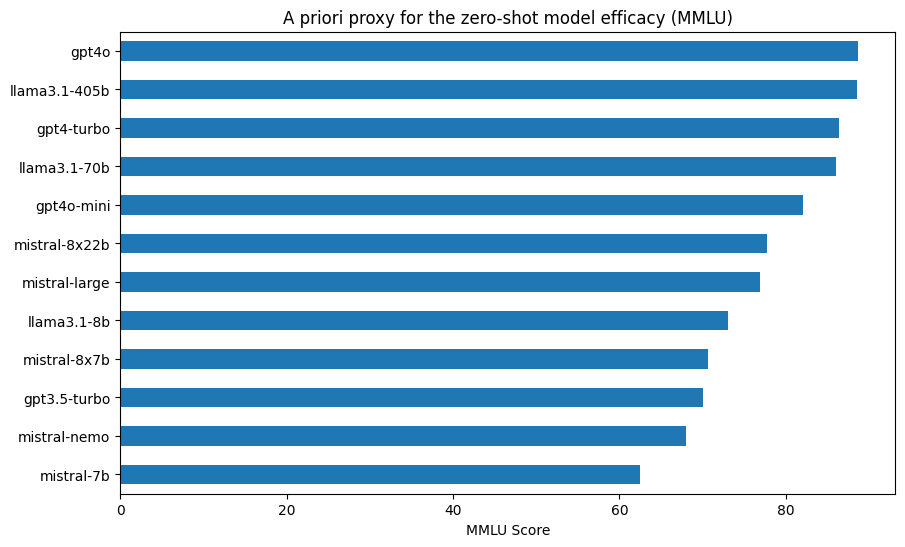

In [10]:
llm.mmlu.dropna().sort_values().plot(
    title='A priori proxy for the zero-shot model efficacy (MMLU)',
    kind='barh', 
    xlabel='MMLU Score', 
    ylabel='', 
    figsize=(10,6)
)

In [11]:
# RUNNING THIS CELL TAKES AGES, RESULTS HAVE BEEN SAVED IN THE FILES OF THE token_counts FOLDER
#from transformers import AutoTokenizer
#from tiktoken import get_encoding
#from llmlingua import PromptCompressor
#
#### GLOBAL
#with open('prompt.txt', encoding="utf8") as f:
#    prompt = f.read()
#
#tiktoken_keys = {
#    'gpt3.5-turbo': 'cl100k_base', # source: https://github.com/openai/tiktoken/blob/main/tiktoken/model.py
#    'gpt4-turbo'  : 'cl100k_base',
#    'gpt4o'       : 'o200k_base',
#    'gpt4o-mini'  : 'o200k_base',
#}
#
#compressor = PromptCompressor('microsoft/llmlingua-2-bert-base-multilingual-cased-meetingbank', use_llmlingua2=True)  
#
#### FUNC
#def token_counts(id, key, preprocessing):
#    func = None
#    if key is None:
#        tok  = get_encoding(tiktoken_keys[id])
#        func = lambda text: tok.encode(text)
#    else:
#        tok  = AutoTokenizer.from_pretrained(key)
#        func = lambda text: tok.encode(text, truncation=False)
#    
#    def _token_counts(text):
#        input = preprocessing(text)
#        return len(func(input))
#    return _token_counts
#
#def process_dataset(preprocessing):
#    ds = pd.read_parquet('brabant-xvii.parquet')
#    for i,k in llm['key'].items():
#        func  = token_counts(i, k, preprocessing)
#        ds[i] = ds['text'].map(func)
#    return ds
#
#### ACTUAL PROCESSING
#print("no_prompt")
#no_prompt = process_dataset(lambda text: text)
#no_prompt.to_parquet('token_counts/no_prompt.parquet', compression='gzip')
#
#print("with prompt")
#with_prompt = process_dataset(lambda text: f'{prompt}\n{text}')
#with_prompt.to_parquet('token_counts/with_prompt.parquet', compression='gzip')
#
#print("with compression")
#with_compression = process_dataset(lambda text: compressor(f'{prompt}\n{text}')['compressed_prompt'])
#with_compression.to_parquet('token_counts/with_compression.parquet', compression='gzip')
no_prompt        = pd.read_parquet('token_counts/no_prompt.parquet').set_index(['project', 'file_id', 'split'])
with_prompt      = pd.read_parquet('token_counts/with_prompt.parquet').set_index(['project', 'file_id', 'split'])
with_compression = pd.read_parquet('token_counts/with_compression.parquet').set_index(['project', 'file_id', 'split'])

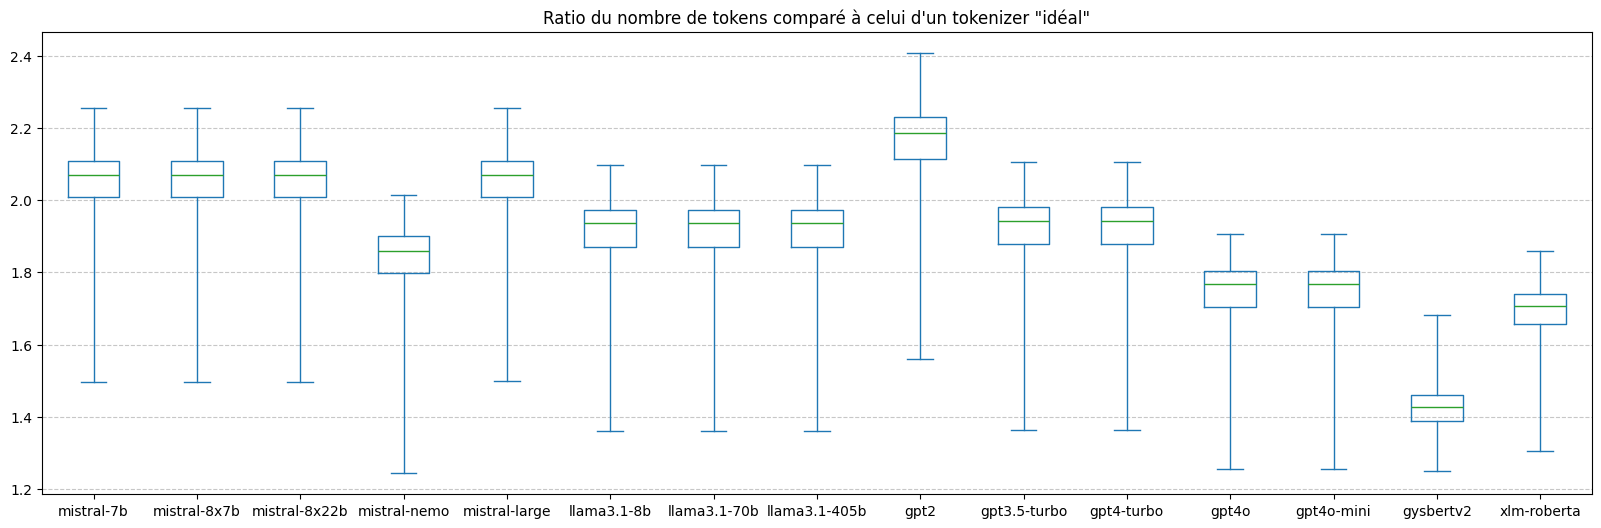

In [12]:
df = pd.DataFrame()
for k in no_prompt.columns[2:]:
    df[k] = no_prompt[k] / no_prompt['from-scratch']

ordre = [
        # mistral
        'mistral-7b', 'mistral-8x7b', 'mistral-8x22b', 'mistral-nemo', 'mistral-large', 
        # llama 3.1
        'llama3.1-8b', 'llama3.1-70b', 'llama3.1-405b',
        # gpt
        'gpt2', 'gpt3.5-turbo', 'gpt4-turbo', 'gpt4o', 'gpt4o-mini',
        # not generative
        'gysbertv2', 'xlm-roberta'
        ]
ax = df[ordre].plot(kind='box',
        title='Ratio du nombre de tokens comparé à celui d\'un tokenizer "idéal"',
        figsize=(20,6),
        whis=(0, 100),
       )
ax.grid(axis='y', linestyle='--', alpha=0.7)

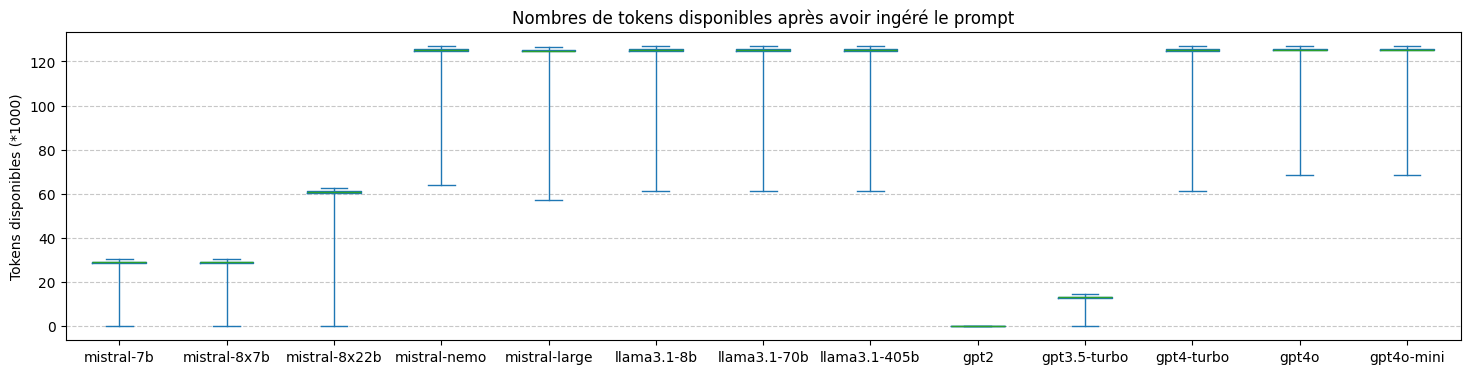

In [13]:
ks = llm[llm['generative']].index
df = pd.concat(list( with_prompt[k] *-1 + llm.loc[k, 'context'] for k in ks), axis=1) # context - token_counts
for k in ks:
    df.loc[df[k]<0, k] = 0
    df[k] /= 1000

ordre = ['mistral-7b', 'mistral-8x7b', 'mistral-8x22b', 'mistral-nemo', 'mistral-large', 
         'llama3.1-8b', 'llama3.1-70b', 'llama3.1-405b',
         'gpt2', 'gpt3.5-turbo', 'gpt4-turbo', 'gpt4o', 'gpt4o-mini',
        ]
ax = df[ordre].plot(kind='box', 
        showfliers=True, 
        title='Nombres de tokens disponibles après avoir ingéré le prompt',
        ylabel ='Tokens disponibles (*1000)',
        figsize=(18,4),
        whis=(0, 100),
     )
ax.grid(axis='y', linestyle='--', alpha=0.7)

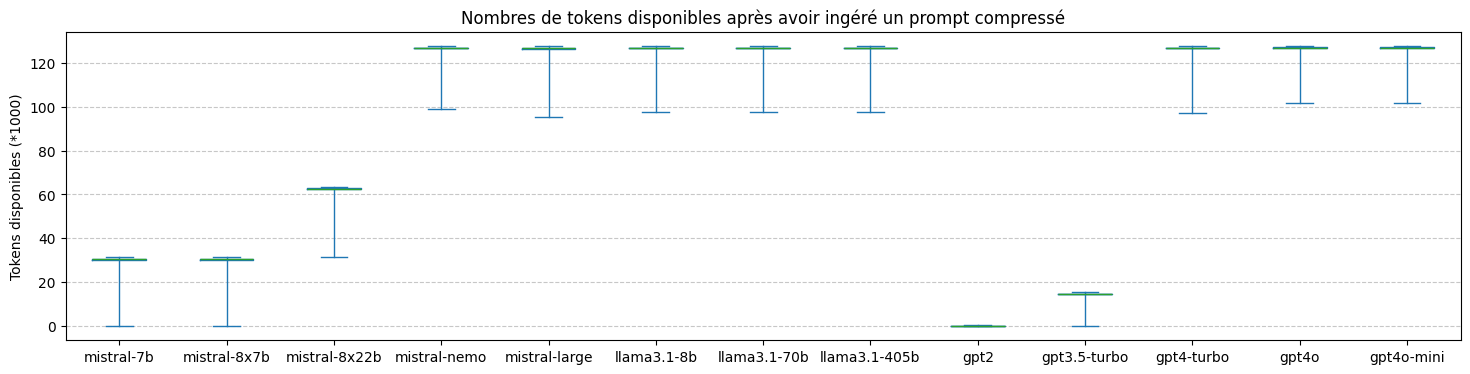

In [14]:
# Using compressed prompts
ks = llm[llm['generative']].index
df = pd.concat(list( with_compression[k] *-1 + llm.loc[k, 'context'] for k in ks), axis=1)
for k in ks:
    df.loc[df[k]<0, k] = 0
    df[k] /= 1000

ordre = ['mistral-7b', 'mistral-8x7b', 'mistral-8x22b', 'mistral-nemo', 'mistral-large', 
         'llama3.1-8b', 'llama3.1-70b', 'llama3.1-405b',
         'gpt2', 'gpt3.5-turbo', 'gpt4-turbo', 'gpt4o', 'gpt4o-mini',
        ]
ax = df[ordre].plot(kind='box', 
        showfliers=True, 
        title='Nombres de tokens disponibles après avoir ingéré un prompt compressé',
        ylabel ='Tokens disponibles (*1000)',
        figsize=(18,4),
        whis=(0, 100),
        )
ax.grid(axis='y', linestyle='--', alpha=0.7)

In [15]:
(llm.params.dropna().sort_values() * 2 / 1024**3)

id
from-scratch       0.195578
gysbertv2          0.203028
gpt2               0.255182
xlm-roberta        1.041219
mistral-7b        13.504177
llama3.1-8b       14.957041
mistral-nemo      22.724271
mistral-8x7b      86.985528
llama3.1-70b     130.496919
mistral-large    229.105353
mistral-8x22b    262.632966
gpt3.5-turbo     325.962901
llama3.1-405b    754.371285
Name: params, dtype: float64

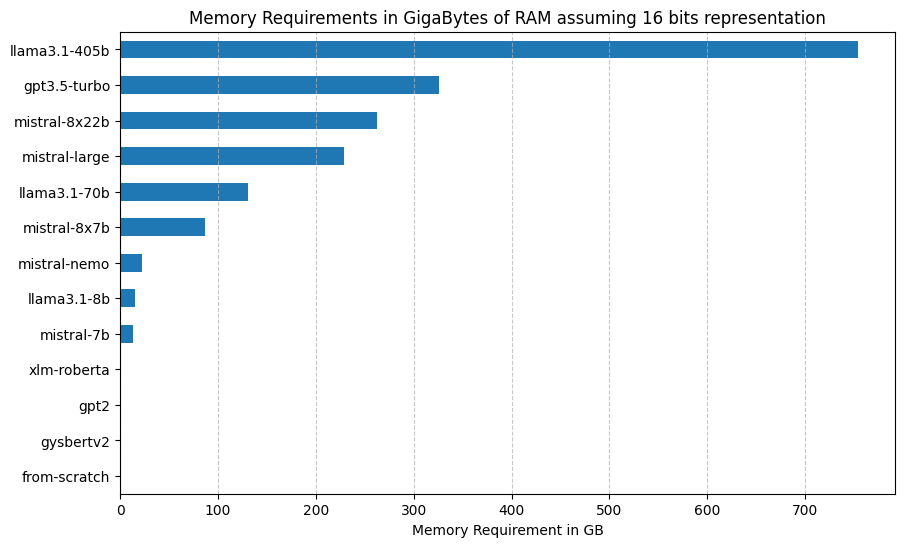

In [16]:
ax = (llm.params.dropna().sort_values() * 2 / 1024**3).plot(
    title ='Memory Requirements in GigaBytes of RAM assuming 16 bits representation',
    kind='barh', 
    ylabel='',
    xlabel='Memory Requirement in GB', 
    figsize=(10,6)
)
ax.grid(axis='x', linestyle='--', alpha=.7)

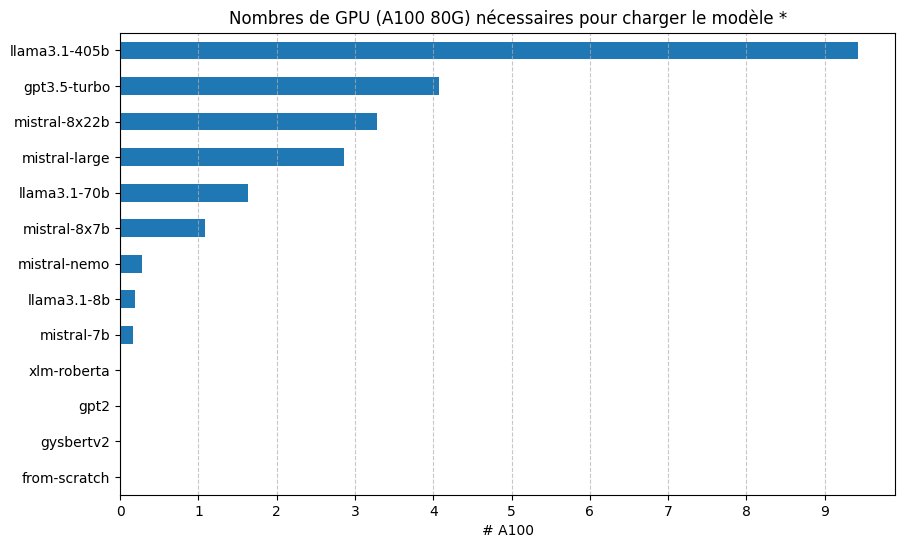

In [17]:
ax = (llm.params.dropna().sort_values() * 2 / 1024**3 / 80).plot(
    title ='Nombres de GPU (A100 80G) nécessaires pour charger le modèle *',
    kind='barh', 
    ylabel='',
    xlabel='# A100', 
    xticks=range(10),
    figsize=(10,6)
)
ax.grid(axis='x', linestyle='--', alpha=0.7)

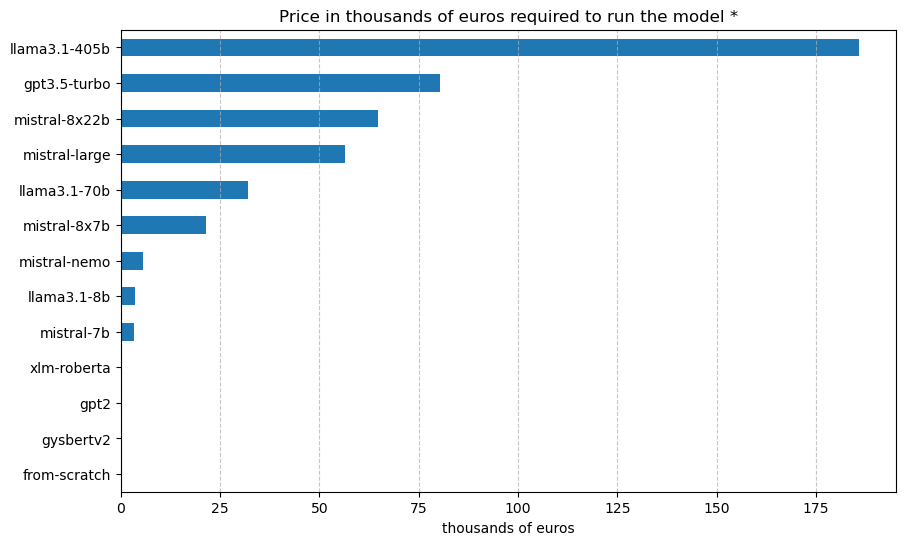

In [27]:
ax = (llm.params.dropna().sort_values() * 2 / 1024**3 / 80 * 19.700).plot(
    title ='Price in thousands of euros required to run the model *',
    kind='barh', 
    ylabel='',
    xlabel='thousands of euros', 
    figsize=(10,6)
)
ax.grid(axis='x', linestyle='--', alpha=0.7)

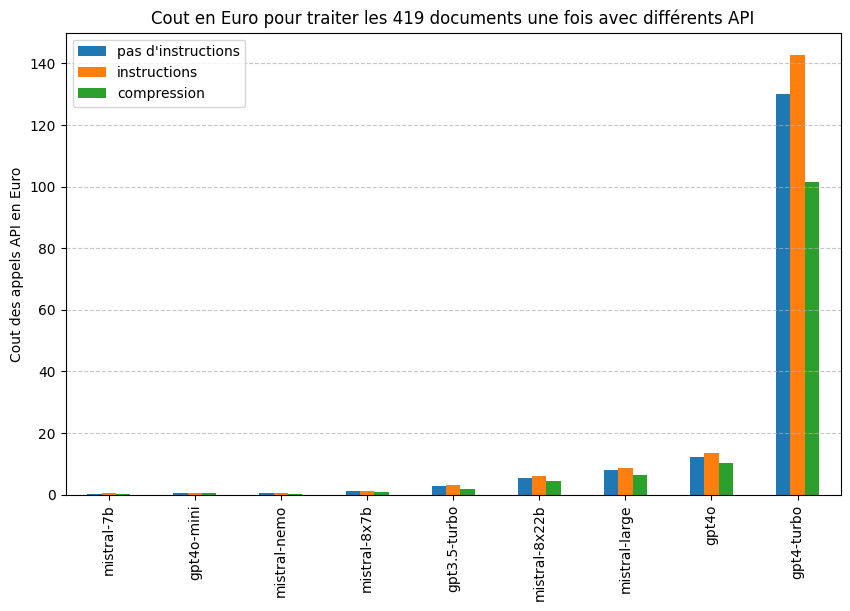

In [22]:
# HYPOTHESIS: The LLM response amounts to about 20% of the original text.

def cloud_price(token_counts):
    mtok   = token_counts[llm[['in', 'out']].dropna().index].sum(axis=0) / 1e6
    nude   = no_prompt[llm[['in', 'out']].dropna().index].sum(axis=0) / 1e6
    return ((mtok * llm['in'].dropna()) + (nude * llm['out'].dropna() / 2)).sort_values()

df = pd.DataFrame()
df['pas d\'instructions'] = cloud_price(no_prompt)
df['instructions']    = cloud_price(with_prompt)
df['compression']     = cloud_price(with_compression)

df.sort_values(['instructions', 'pas d\'instructions', 'compression'], inplace=True)

ax = df.plot(
    kind='bar',
    title='Cout en Euro pour traiter les 419 documents une fois avec différents API',
    ylabel='Cout des appels API en Euro',
    figsize=(10,6)
)
ax.grid(axis='y', linestyle='--', alpha=0.7)

In [43]:
llm[['in','out','mmlu', 'context']].dropna().sort_values(['in', 'out'])

,in,out,mmlu,context
id,,,,
gpt4o-mini,0.15,0.60,82.00,128000.0
mistral-7b,0.20,0.20,62.50,32000.0
mistral-nemo,0.27,0.27,68.00,128000.0
mistral-8x7b,0.65,0.65,70.60,32000.0
gpt3.5-turbo,1.50,2.00,70.00,16000.0
mistral-8x22b,1.90,5.60,77.75,64000.0
mistral-large,2.70,8.20,76.90,128000.0
gpt4o,5.00,15.00,88.70,128000.0
gpt4-turbo,60.00,120.00,86.40,128000.0


## Conclusion

gpt4o-mini est un excellent choix pour cette application. Comme il y a beaucoup plus de texte en entrée qu'en sortie, la différence de 7ct par 1M tokens en entrée pèse plus que la différence de 40ct/1M tokens en sortie. Le fait que **gpt4o-mini** ait un score MMLU de 82 et une fenêtre de contexte de 128k tokens le rend particulièrement attractif. A fortiori si on considère que sa tokenisation est l'une des meilleure pour notre dataset: environ1.75 fois plus de tokens que pour un tokenizer entrainé sur les données cibles. C'est à dire à peu près autant que le tokenizer de xlm-roberta, mais évidemment moins bon que gysbert qui s'avère être assez proche de l'optimum (environ 1.45 fois plus de tokens que l'optimum).

In [47]:
df.sort_values('instructions')

,no instructions,instructions,compression
mistral-7b,0.347503,0.395787,0.246700
gpt4o-mini,0.443965,0.475767,0.378097
mistral-nemo,0.419444,0.478498,0.295446
mistral-8x7b,1.129384,1.286308,0.801776
gpt3.5-turbo,2.709548,3.028197,1.991480
mistral-8x22b,5.444212,5.902912,4.486587
mistral-large,7.877256,8.528885,6.516213
gpt4o,12.332350,13.392420,10.136755
gpt4-turbo,130.058280,142.804260,101.335560


In [52]:
llm[llm['key'].notnull() & llm['fits_a100_80'] & llm['generative']]

,key,context,params,in,out,mmlu,fits_a100_80,generative
id,,,,,,,,
gpt2,openai-community/gpt2,1024.0,1.370000e+08,NaN,NaN,NaN,True,True
llama3.1-8b,meta-llama/Meta-Llama-3.1-8B-Instruct,128000.0,8.030000e+09,NaN,NaN,73.0,True,True
mistral-7b,mistralai/Mistral-7B-Instruct-v0.3,32000.0,7.250000e+09,0.20,0.20,62.5,True,True
mistral-nemo,mistralai/Mistral-Nemo-Instruct-2407,128000.0,1.220000e+10,0.27,0.27,68.0,True,True
